# Organising the Dataset

Before we can start downloading and preprocessing medical imaging data we need to first clean and process the dataset, reducing it to only sessions that meet our requirements. The requirements being:

1. Simplify clinical diagnoses into binary labels.
2. Find the most common MRI type and select sessions
3. For each MRI find a corresponding PET session that is within 6 months
4. Apply labeled diagnosis with historical diagnoses data

## Reading the data

The Oasis 3 dataset supplies a folder with data about the MRI and PET scans, as well as the subjects and diagnosis. This data is fragmented into multiple csv files and an MRI scan does not necessarily have a corresponding PET scan. Some entries contain errors or null values that need to be dropped or replaced.

In [ ]:
import os
import re
import pandas as pd
import numpy as np

random_seed = 42

data_path = "/home/kamran/projects/final-project/src/dataset/OASIS3_data_files/"

healthy_data = pd.read_csv(os.path.join(data_path, "CogNorm-Cognitively_Normal_Cohorts/OASIS3_unchanged_CDR_cognitively_healthy.csv"))
cdr_data = pd.read_csv(os.path.join(data_path, "UDSb4-Form_B4__Global_Staging__CDR__Standard_and_Supplemental/OASIS3_UDSb4_cdr.csv"))
diag_data = pd.read_csv(os.path.join(data_path, "UDSd1-Form_D1__Clinician_Diagnosis___Cognitive_Status_and_Dementia/OASIS3_UDSd1_diagnoses.csv"))
mri_data = pd.read_csv(os.path.join(data_path, "MRI-json-MRI_json_information/OASIS3_MR_json.csv"))
pet_data = pd.read_csv(os.path.join(data_path, "PET-json-PET_json_information/OASIS3_PET_json.csv"))
pup_data = pd.read_csv(os.path.join(data_path, "PUP-PUP_output/OASIS3_PUP.csv"))


str_cols = ['OASISID', 'OASIS_session_label', 'dx1', 'dx2', 'dx3', 'dx4', 'dx5']
cdr_data[str_cols] = cdr_data[str_cols].apply(lambda s: s.astype(str))

# Find all cognitively healthy participants
healthy_ids = [str(x) for x in healthy_data['OASIS3_id'].unique()]
cdr_data_healthy = cdr_data[cdr_data['CDRTOT'] == 0]
cdr_healthy_ids = [str(x) for x in cdr_data_healthy.OASISID.unique()]

print("Received Healthy Diagnoses:",len(cdr_healthy_ids))
print("Unchanged Healthy:", len(healthy_ids))
difference = set(cdr_healthy_ids).difference(set(healthy_ids))
print("Converted:", len(difference))

Received Healthy Diagnoses: 1076
Unchanged Healthy: 755
Converted: 321


We can see that of 1076 patients who received a cognitively healthy evaluation, only 755 remained cognitively healthy throughout the study, with 321 patients having received a higher CDR score and evaluation, indicating potential dementia. This data could be potentially useful for detecting earlier signs of dementia.

### Simplifying Categories

Here I am simplifying the diagnosis labels into two categories DEMENTED and NON-DEMENTED, any values that don't fall into these categories are discarded. Where values are missing, there is an attempt to reconstruct the correct value by comparing the patient ID to known healthy individuals, and finding an average diagnosis from the CDR data where multiple clinical diagnosis is available.

In [ ]:
diag_df = diag_data[['OASISID', 'OASIS_session_label', 'days_to_visit','age at visit', 'NORMCOG', 'DEMENTED']].copy()
diag_df.replace({np.nan: None}, inplace=True)

print("Initial Count:")
print("Dementia:", diag_df[diag_df.DEMENTED == 1].OASISID.count())
print("Normal:", diag_df[diag_df.NORMCOG == 1].OASISID.count())
print("---------------------")

def convert(d):
    keywords = ['DAT',
                'AD dem',
                'Vascular dem',
                'Frontotemporal dem',
                'Active PSNP',
                'Dementia', 'DLBD',
                'Incipient demt',
                'Uncertain dementia']
    if re.match(f'^({"|".join(keywords)})', d, re.I):
        return 1
    elif re.match(f'^unc', d, re.I):
        return 0.5
    else:
        return 0


for index, row in diag_df.iterrows():
    if row['NORMCOG'] == 1:
        diag_df.at[index, 'DEMENTED'] = 0
    elif row['DEMENTED'] == 1:
        diag_df.at[index, 'NORMCOG'] = 0
    elif row['NORMCOG'] == None and row['OASISID'] in healthy_ids:
        diag_df.at[index, 'NORMCOG'] = 1
        diag_df.at[index, 'DEMENTED'] = 0
    elif row['NORMCOG'] == 0 and (row['DEMENTED'] == 0 or row['DEMENTED'] == None):
        diag_df.drop(index, inplace=True)

    # Classify demented using consensus evaluation
    elif row['NORMCOG'] == None:
        day = row['days_to_visit']
        search = cdr_data.loc[(cdr_data['days_to_visit'].between(day-3, day+4)) &
                      (cdr_data['OASISID'] == row['OASISID'])].values.tolist()
        if len(search) == 0:
            diag_df.drop(index, inplace=True)
            continue
        else:
            search = search[0]

        sum = 0
        check = 0
        if search[18] in ['.', 'A']:
            diag_df.drop(index, inplace=True)
            continue
        for i in range(5):
            if search[18+i] == '.':
                continue
            elif search[18+i] == 'A':
                sum += convert(search[18])
            else:
                sum += convert(search[18+i])
            check += 1

        # range to discard average
        avg = float(sum) / check
        if avg >= 0.8:
            diag_df.at[index, 'NORMCOG'] = 1 - round(avg)
            diag_df.at[index, 'DEMENTED'] = round(avg)

        elif avg > 0.2:
            diag_df.drop(index, inplace=True)

        elif search[12] == 0:
            diag_df.at[index, 'NORMCOG'] = 1
            diag_df.at[index, 'DEMENTED'] = 0

print("Dementia:", diag_df.DEMENTED.value_counts())
diag_df.to_csv("diagnosis.csv")

Initial Count:
Dementia: 1378
Normal: 5799
---------------------
Dementia: DEMENTED
0      6413
1.0    1472
Name: count, dtype: int64


### Label Correction

It is hard to tell when dementia is present, because of this a subject may have multiple positive scans succeeded by multiple negative scans. We use a 2N neighbour comparison algorithm to try and correct anamolies in the data. This should show good correlation to disease progression on the MRIs.

Dementia: DEMENTED
0    6549
1    1343
Name: count, dtype: int64


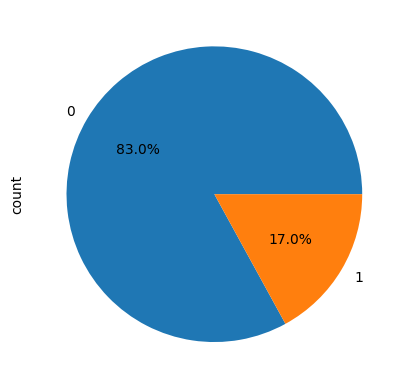

In [ ]:
diag_df = diag_df.sort_values(by=['OASISID', 'days_to_visit']).reset_index(drop=True)
current_subj = None
for index, row in diag_df.iterrows():
    if current_subj != row['OASISID']:
        current_subj = row['OASISID']
        prec = (None, None) # i-2, i-1
        succ = (diag_df.at[index + 1, 'DEMENTED'] if index + 1 < diag_df.shape[0] and diag_df.at[index + 1, 'OASISID'] == current_subj else None,
                diag_df.at[index + 2, 'DEMENTED'] if index + 2 < diag_df.shape[0] and diag_df.at[index + 2, 'OASISID'] == current_subj else None)

    if row['DEMENTED'] == True:
        new = int(prec[1] or any(succ))
    else:
        new = int(any(prec) and any(succ))
    diag_df.at[index, 'DEMENTED'] = new

    prec = (prec[1], new) # i-1, i
    succ = (succ[1], diag_df.at[index + 3, 'DEMENTED'] if index + 3 in diag_df.index and diag_df.at[index + 3, 'OASISID'] == current_subj else None)

print("Dementia:", diag_df.DEMENTED.value_counts())
diag_df['DEMENTED'].value_counts().plot.pie(autopct='%1.1f%%')
diag_df.to_csv("diagnosis.csv")


### Reading the PUP data

The PET Unified Pipeline is an association of MRI and PET scans that have undergone standardization, because these MRI and PET scans are already associated and standardized all we need to do is label them. I am creating a new dataframe for the labeled results, removing unneccessary columns.

In [13]:
labeled_dataset = pup_data.copy()

# Removing unncessary columns
labeled_dataset.drop(columns = ['procType', 'model'])
labeled_dataset.drop(columns = labeled_dataset.columns[labeled_dataset.columns.str.startswith('PET_fBP')], inplace = True)
labeled_dataset.drop(columns = labeled_dataset.columns[labeled_dataset.columns.str.startswith('PET_fSU')], inplace = True)

### Combining the PUP (Pet Unified Pipeline) with Labels

label
False    1681
True      150
Name: count, dtype: int64


<Axes: ylabel='count'>

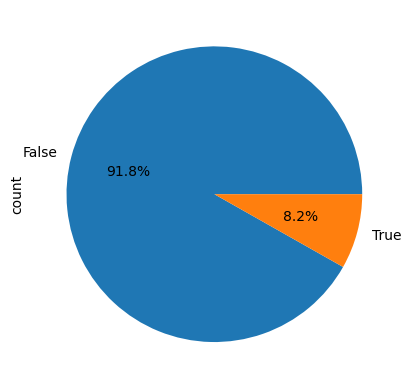

In [14]:
labeled_dataset['label'] = None

for index, row in labeled_dataset.iterrows():
    # Get subject name and day
    subject = row['MRId'].split("_")[0]
    time = int(row['PUP_PUPTIMECOURSEDATA ID'].split('_')[-1][1:])

    # Search diagnosis for entries with subject
    rows_of_subject = diag_df.loc[diag_df['OASISID'] == row['MRId'].split("_")[0]][['days_to_visit', 'DEMENTED']]
    # Calculate time offset
    rows_of_subject['days_to_visit'] = rows_of_subject['days_to_visit'].apply(lambda x: abs(x - time))

    try:
        labeled_dataset.at[index,'label'] = (rows_of_subject.groupby(by='days_to_visit', as_index=False)
                                                            .any()
                                                            .sort_values(by='days_to_visit')
                                                            .loc[0]['DEMENTED'])
    except KeyError:
        labeled_dataset.drop(index, inplace=True)

print(labeled_dataset['label'].value_counts())

# Add time subject and time column
subject = [s.split('_')[0] for s in labeled_dataset['PUP_PUPTIMECOURSEDATA ID']]
day = [int(s.split('_')[-1][1:]) for s in labeled_dataset['PUP_PUPTIMECOURSEDATA ID']]

if 'OASISID' not in labeled_dataset:
    labeled_dataset.insert(loc=0, column='OASISID', value=subject)
    labeled_dataset.insert(loc=2, column='days_to_visit', value=day)
labeled_dataset['label'].value_counts().plot.pie(autopct='%1.1f%%')

Because it is very hard to diagnose early onset dementia, I will be using the first and last MRIs of patients who were initially tested as healthy and were subsequently diagnosed with dementia. For the patients that were healthy throughout the study, I shall only use the first MRI that was taken as that is the point were the brain is most likely to be free of abnormalities or undiagnosed dementia, this will also help avoid future bias where little variance is observed over time in healthy individuals causing overfitting.

### Adding associated PET scan

In [ ]:
str_cols = ['OASISID', 'OASIS_session_label', 'dx1', 'dx2', 'dx3', 'dx4', 'dx5']

def correct_date(s: str):
    date = s.split('_')[-1]
    if len(date) != 5:
        return s.replace('_d', '_d' + ((5-len(date)) * '0'))
    else:
        return s

# Correct day format to include missing zeroes
pet_data['session_id'] = pet_data['session_id'].apply(lambda s: correct_date(s))
# Match PUP ids to PET id format
if 'id' in labeled_dataset:
    labeled_dataset['id'] = labeled_dataset['id'].apply(lambda s: str(s).replace("PUPTIMECOURSE_", ""))
    labeled_dataset.rename(columns={"id": "PET_id"}, inplace=True)
labeled_dataset.to_csv('labeled_dataset.csv', index=False)


# Find all unique PET sessions in PUP
pup_pet_set = set(labeled_dataset['PET_id'].unique())

# Check number of pup sessions without pet entry
print("Difference between PUP and PET:",len(pup_pet_set - set(pet_data['session_id'].unique())))

# Find all unique MRI sessions in PUP
pup_mri_set = set(labeled_dataset['MRId'].unique())

# Check number of pup sessions with mri entry
print("Difference between PUP and MRI:",len(pup_mri_set - set(mri_data['label'].unique())))

print(list(pup_mri_set - set(mri_data['label'].unique()))[:5])

Difference between PUP and PET: 0
Difference between PUP and MRI: 20
['OAS30078_MR_d0136', 'OAS30119_MR_d1615', 'OAS30053_MR_d1393', 'OAS30525_MR_d0118', 'OAS31111_MR_d0089']


### Validating MRI Scans

### Removing duplicates

Because it is very hard to diagnose early onset dementia, I will be using the first and last MRIs of patients who were initially tested as healthy and were subsequently diagnosed with dementia. For the patients that were healthy throughout the study, I shall only use the first MRI that was taken as that is the point were the brain is most likely to be free of abnormalities or undiagnosed dementia, this will also help avoid future bias where little variance is observed over time in healthy individuals causing overfitting.

Healthy: 644
Demented: 134


<Axes: ylabel='count'>

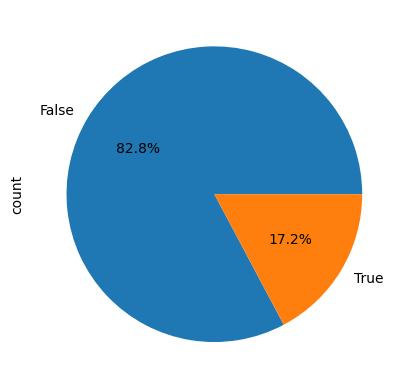

In [ ]:
healthy_labeled = labeled_dataset[labeled_dataset['OASISID'].isin(healthy_ids)]
healthy_labeled = healthy_labeled.sort_values(['OASISID','days_to_visit'], ascending=[True,True])
healthy_labeled.drop_duplicates(subset=['OASISID'], keep='first', inplace=True)

demented_labeled = labeled_dataset[labeled_dataset['label'] == 1]
# Experiment for isolating subjects with more than 1 diagnosis
# i.e., more than 1 demented entry, only yields 12 entries (unfeasible)
# ids = demented_labeled.OASISID
# demented_labeled = demented_labeled[ids.isin(ids[ids.duplicated()])]
demented_labeled = demented_labeled.sort_values(['OASISID','days_to_visit'], ascending=[True,True])
demented_labeled.drop_duplicates(subset=['OASISID'], keep='last', inplace=True)

print("Healthy:", healthy_labeled.OASISID.count())
print("Demented:", demented_labeled.OASISID.count())

labeled_dataset = pd.concat([healthy_labeled, demented_labeled], axis=0).reset_index(drop=True)
labeled_dataset.to_csv('labeled_dataset.csv', index=False)
labeled_dataset['label'].value_counts().plot.pie(autopct='%1.1f%%')

### Balancing the dataset

The number of negative samples far outweight the number of positive samples, in order to effectively balance the dataset undersampling of the majority class is the best option as with complex data like MRIs oversampling techniques will likely fail or generate useless data that could negatively impact the result. We undersample to the healthy samples maintain data integrity. Data augmentation techniques can also be used to increase the number of positive samples while increasing the generalisation ability of the model.

In [17]:
# Take 150 samples at random from the healthy dataset using set seed
healthy_labeled = healthy_labeled.sample(n = 150, random_state=random_seed)

<Axes: ylabel='count'>

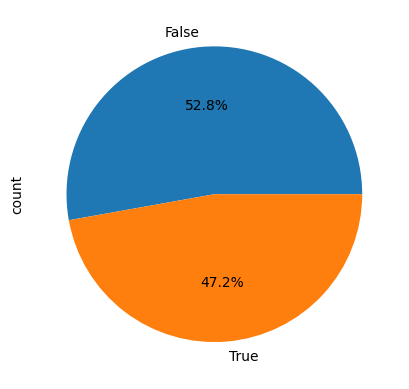

In [ ]:
labeled_dataset = pd.concat([healthy_labeled, demented_labeled], axis=0).reset_index(drop=True)
labeled_dataset.to_csv('balanced_dataset.csv', index=False)
labeled_dataset['PUP_PUPTIMECOURSEDATA ID'].to_csv('dataset_download.csv', index=False)
labeled_dataset['label'].value_counts().plot.pie(autopct='%1.1f%%')